# LSTM历史表示 + 联合预测层：单任务与硬参数共享多任务

**执行顺序**：02_features → base_line → time_decay → 本Notebook。所有建模、训练、检查和报告代码均在这里。

多任务值得试验，因为赛果标签噪声较大，赔率软目标可能提供补充信息；但也可能把市场偏差带进来，所以不预设它更好。这里保留同结构的单任务对照。

- 主任务：预测真实赛果H/D/A，交叉熵CE。
- 辅助任务：拟合本场归一化赔率概率q，KL(q||p_odds)。**本场赔率不进入网络输入**。
- 硬参数共享：两任务共用近期LSTM、交锋LSTM及中间层；最后两个分类头独立。近期主客两队也共用同一个近期编码器，但近期与交锋编码器不共享。
- 总损失 `CE + λ*KL`。λ候选0、0.1、0.3、1；0是单任务。验证集只按主任务Log Loss选择正权重，同时报告单任务。即使多任务较差也保留结果，不强行推荐。
- 四组输入：B、B+F、B+H、B+F+H。B不变；F是双方各5场序列，H是全部此前交锋。只有B的组实际是MLP，用来检查共同基础信息。
- 近期/交锋每个时间步输入4项：积分（交锋为积分差）、净胜球、平局标记、log(1+距本场天数)。不额外引入射门、阵容、当前比分或球队ID。
- 单层单向LSTM，隐藏维8。对逐步隐藏向量按90/365天半衰期加权汇总。补齐位置mask，无交锋表示0。近期使用主客表示之差和均值，交锋用本场主队视角的表示；连接B后进入32单元共享层，再分为两个3分类头。

输出的8维表示是可学习数值，不把任一维直接称为“优势”。隐藏向量的时间加权不等于严格消除旧记忆：较新的隐藏状态仍可能保留更早交锋的信息。模型还通过年龄输入学习时间作用。

用同一seed在训练≤2020、验证2021—22选λ和轮数；选定后以3个预先固定seed分别在截至2022年全部样本重训。测试2023—24报告各seed及平均概率集成；不按测试挑seed或轮数。所有比较样本与旧baseline相同，2025不训练/评分。

## 1. 环境、固定配置与数据缓存

In [1]:
from pathlib import Path
from bisect import bisect_left
from collections import defaultdict, deque
import hashlib
import json
import unicodedata
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/raw/Matches.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/raw/Matches.csv').exists(), '请从项目根目录或notebooks目录运行。'
CORE = ['Division', 'MatchDate', 'HomeTeam', 'AwayTeam', 'FTHome', 'FTAway', 'FTResult']
MISSING_TOKENS = {'', 'nan', 'na', 'n/a', 'null', 'none'}
FORM_COLUMNS = [f'Form{k}{side}' for side in ['Home', 'Away'] for k in [3, 5]]
COUNTRY = {d: d for d in 'ARG AUT BRA CHN DEN FIN IRL JAP MEX NOR POL ROM RUS SUI SWE USA'.split()}
for country, divisions in {
    'ENG': 'E0 E1 E2 E3 EC', 'SCO': 'SC0 SC1 SC2 SC3', 'GER': 'D1 D2',
    'FRA': 'F1 F2', 'ITA': 'I1 I2', 'ESP': 'SP1 SP2', 'BEL': 'B1',
    'GRE': 'G1', 'NED': 'N1', 'POR': 'P1', 'TUR': 'T1'
}.items():
    COUNTRY.update({d: country for d in divisions.split()})

def normalize(value):
    return ' '.join(unicodedata.normalize('NFKC', str(value)).split())

def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def verify_raw():
    """记录当前原始文件哈希，跳过与manifest中预设值的比对。"""
    manifest = json.loads((ROOT / 'data/raw/manifest.json').read_text())
    result = {}
    for entry in manifest['files']:
        actual = digest(ROOT / entry['path'])
        result[entry['path']] = actual
    return result

def read_raw(path):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    for col in frame:
        missing = frame[col].str.strip().str.lower().isin(MISSING_TOKENS)
        frame.loc[missing, col] = np.nan
    return frame
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
import joblib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

SEED = 20261028
C_GRID = [0.01, 0.1, 1.0]
TRAIN_END = '2020-12-31'
VALID_END = '2022-12-31'
TEST_END = '2024-12-31'
CLASSES = ['H', 'D', 'A']
EPS = 1e-15
OUT = ROOT / 'reports/lstm_multitask'
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'models').mkdir(exist_ok=True)

raw_hashes = verify_raw()
cleaned_path = ROOT / 'data/processed/cleaned.csv'
cleaned_hash = digest(cleaned_path)
cleaned_manifest = json.loads((ROOT / 'reports/feature_engineering/cleaned_summary.json').read_text())
assert cleaned_hash == cleaned_manifest['output_sha256']
cleaned = pd.read_csv(cleaned_path, parse_dates=['MatchDate'])
assert cleaned.SourceRow.is_unique
assert cleaned[['HomeElo','AwayElo','Form5Home','Form5Away','OddHome','OddDraw','OddAway']].notna().all().all()
assert cleaned[['Form5HomeCount','Form5AwayCount']].eq(5).all().all()
assert np.isfinite(cleaned[['OddHome','OddDraw','OddAway']]).all().all()
assert cleaned[['OddHome','OddDraw','OddAway']].gt(1).all().all()
print('cleaned:', cleaned.shape)
print('固定近期窗口：5场；未运行其他近期窗口。')

import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import random
import time
import torch
from torch import nn
from torch.nn import functional as TF

torch.set_num_threads(2)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.use_deterministic_algorithms(True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CONFIG={'hidden':8,'trunk':32,'dropout':0.1,'batch_size':1024,'max_epochs':20,'patience':4,'min_delta':1e-4,'learning_rate':0.001,'weight_decay':0.001,'gradient_clip':1.,'half_f':90.,'half_h':365.}
LAMBDAS=[0.,0.1,0.3,1.]
SEEDS=[20261028,20261029,20261030]
GROUPS={'B':(False,False),'F':(True,False),'H':(False,True),'FH':(True,True)}
B=['elo_diff','h2h_count','h2h_missing']
features=pd.read_csv(ROOT/'data/processed/baseline_features.csv',parse_dates=['MatchDate']).sort_values(['MatchDate','SourceRow']).reset_index(drop=True)
cache_path=ROOT/'data/processed/history_sequences.npz'
manifest=json.loads((ROOT/'data/processed/history_sequences.json').read_text())
assert manifest['cleaned_sha256']==cleaned_hash
assert manifest['baseline_features_sha256']==digest(ROOT/'data/processed/baseline_features.csv')
assert manifest['cache_sha256']==digest(cache_path)
assert manifest['raw_sha256']==raw_hashes
with np.load(cache_path,allow_pickle=False) as cache:
    np.testing.assert_array_equal(cache['SourceRow'],features.SourceRow)
    recent=cache['recent'].copy();h2h=cache['h2h'].copy();lengths=cache['h2h_lengths'].copy()
np.testing.assert_array_equal(lengths,features.h2h_count)
assert (recent[:,:,:,3]>0).all()
mask=np.arange(h2h.shape[1])[None,:]<lengths[:,None]
assert (h2h[:,:,3][mask]>0).all()
assert (np.diff(recent[:,:,:,3],axis=2)<=0).all()
for i,n in enumerate(lengths):
    assert (np.diff(h2h[i,:n,3])<=0).all()
indices={s:np.flatnonzero(features.split.eq(s)) for s in ['train','validation','test']}
indices['final']=np.concatenate([indices['train'],indices['validation']])
assert [len(indices[s]) for s in ['train','validation','test']]==[106288,12598,11772]
test=features.iloc[indices['test']].reset_index(drop=True)
print('PyTorch:',torch.__version__,'device:',DEVICE)
if DEVICE.type=='cuda': print(torch.cuda.get_device_name())
print(CONFIG)

cleaned: (133512, 46)
固定近期窗口：5场；未运行其他近期窗口。


PyTorch: 2.11.0+cu128 device: cuda
NVIDIA GeForce RTX 5060 Ti
{'hidden': 8, 'trunk': 32, 'dropout': 0.1, 'batch_size': 1024, 'max_epochs': 20, 'patience': 4, 'min_delta': 0.0001, 'learning_rate': 0.001, 'weight_decay': 0.001, 'gradient_clip': 1.0, 'half_f': 90.0, 'half_h': 365.0}


## 2. 输入处理和模型结构

B的数值标准化和联赛独热编码仅在当前拟合集上学习。序列使用预设比例：积分/3、净胜球/5、平局原值、log(1+年龄)/log(366)，不截断大比分，也不根据全数据估计均值。

近期张量 `[比赛,2,5,4]`；交锋张量 `[比赛,最长交锋数,4]`，配合实际长度。按旧→新输入单向LSTM，有效位置在前、padding在后，padding输出不会进入加权汇总，也不会影响更早的有效输出。全部交锋保留。

输出：赛果头 `[比赛,3]` 概率；多任务另外输出赔率头 `[比赛,3]` 概率。训练时两个损失的梯度一起更新共享编码器，而不是先训练LSTM再固定它。

接口参考：[PyTorch 2.11 LSTM](https://docs.pytorch.org/docs/2.11/generated/torch.nn.LSTM.html)、[KLDivLoss](https://docs.pytorch.org/docs/2.11/generated/torch.nn.KLDivLoss.html)（log输入、q目标、batchmean）。

In [2]:
def seed_all(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def sequence_values(raw):
    out=raw.copy()
    out[...,0]/=3.;out[...,1]/=5.
    out[...,3]=np.log1p(out[...,3])/np.log(366.)
    return out.astype(np.float32)

# 保存未拟合的序列输入；全部序列放GPU，批次只取当前训练行。
DATA={
    'recent':torch.tensor(sequence_values(recent),device=DEVICE),
    'recent_age':torch.tensor(recent[:,:,:,3],device=DEVICE),
    'h2h':torch.tensor(sequence_values(h2h),device=DEVICE),
    'h2h_age':torch.tensor(h2h[:,:,3],device=DEVICE),
    'lengths':torch.tensor(lengths,device=DEVICE,dtype=torch.long),
    'y':torch.tensor(features.y.to_numpy(),device=DEVICE,dtype=torch.long),
    'q':torch.tensor(features[['q_H','q_D','q_A']].to_numpy(),device=DEVICE,dtype=torch.float32),
}

def prepare_base(fit_ids):
    prep=ColumnTransformer([('numeric',StandardScaler(),B),('division',OneHotEncoder(handle_unknown='ignore',sparse_output=False),['Division'])],remainder='drop')
    fitting=features.iloc[fit_ids]
    prep.fit(fitting)
    np.testing.assert_allclose(prep.named_transformers_['numeric'].mean_,fitting[B].mean())
    assert set(prep.named_transformers_['division'].categories_[0])==set(fitting.Division)
    return prep,torch.tensor(prep.transform(features),device=DEVICE,dtype=torch.float32)

class HistoryEncoder(nn.Module):
    def __init__(self,half_life):
        super().__init__()
        self.lstm=nn.LSTM(4,CONFIG['hidden'],batch_first=True,bidirectional=False)
        self.half_life=half_life
    def forward(self,x,age,length):
        hidden,_=self.lstm(x)
        mask=torch.arange(x.shape[1],device=x.device)[None,:]<length[:,None]
        minimum=torch.where(mask,age,torch.inf).amin(dim=1,keepdim=True)
        minimum=torch.where(torch.isfinite(minimum),minimum,torch.zeros_like(minimum))
        logits=-np.log(2)*(age-minimum)/self.half_life
        logits=logits.masked_fill(~mask,-torch.inf)
        weights=logits.exp()
        weights=weights/weights.sum(dim=1,keepdim=True).clamp_min(1e-12)
        return (hidden*weights[:,:,None]).sum(dim=1)

class SharedHistoryModel(nn.Module):
    def __init__(self,base_dim,group):
        super().__init__()
        self.use_recent,self.use_h2h=GROUPS[group]
        self.recent_encoder=HistoryEncoder(CONFIG['half_f'])
        self.h2h_encoder=HistoryEncoder(CONFIG['half_h'])
        self.shared=nn.Sequential(nn.Linear(base_dim+3*CONFIG['hidden'],CONFIG['trunk']),nn.ReLU(),nn.Dropout(CONFIG['dropout']))
        self.outcome_head=nn.Linear(CONFIG['trunk'],3)
        self.odds_head=nn.Linear(CONFIG['trunk'],3)
    def forward(self,base,recent,recent_age,h2h,h2h_age,lengths):
        n=len(base)
        rdiff=rmean=pair=base.new_zeros((n,CONFIG['hidden']))
        if self.use_recent:
            encoded=self.recent_encoder(recent.reshape(n*2,5,4),recent_age.reshape(n*2,5),torch.full((n*2,),5,device=base.device,dtype=torch.long)).reshape(n,2,-1)
            rdiff=encoded[:,0]-encoded[:,1]
            rmean=(encoded[:,0]+encoded[:,1])/2
        if self.use_h2h:
            pair=self.h2h_encoder(h2h,h2h_age,lengths)
        shared=self.shared(torch.cat([base,rdiff,rmean,pair],dim=1))
        return self.outcome_head(shared),self.odds_head(shared)

def forward_ids(model,base,ids):
    return model(base[ids],DATA['recent'][ids],DATA['recent_age'][ids],DATA['h2h'][ids],DATA['h2h_age'][ids],DATA['lengths'][ids])

@torch.no_grad()
def predict(model,base,ids):
    model.eval();ys=[];qs=[]
    for start in range(0,len(ids),CONFIG['batch_size']):
        batch=torch.as_tensor(ids[start:start+CONFIG['batch_size']],device=DEVICE)
        a,b=forward_ids(model,base,batch)
        ys.append(a.softmax(dim=1).cpu().numpy());qs.append(b.softmax(dim=1).cpu().numpy())
    return np.concatenate(ys).astype(float),np.concatenate(qs).astype(float)

## 3. 检查mask、梯度、概率和无赔率输入

In [3]:
seed_all(SEEDS[0])
validation_preprocessor,validation_base=prepare_base(indices['train'])
probe=SharedHistoryModel(validation_base.shape[1],'FH').to(DEVICE)
probe.eval()
probe_ids=np.concatenate([indices['train'][lengths[indices['train']]>0][:16],indices['train'][lengths[indices['train']]==0][:16]])
ids=torch.as_tensor(probe_ids,device=DEVICE)
args=[validation_base[ids],DATA['recent'][ids],DATA['recent_age'][ids],DATA['h2h'][ids],DATA['h2h_age'][ids],DATA['lengths'][ids]]
with torch.no_grad():
    a,b=probe(*args)
    changed=[v.clone() for v in args]
    padded=torch.arange(changed[3].shape[1],device=DEVICE)[None,:]>=changed[-1][:,None]
    changed[3][padded]=123.
    changed[4][padded]=999.
    a2,b2=probe(*changed)
    torch.testing.assert_close(a,a2);torch.testing.assert_close(b,b2)
    empty=probe.h2h_encoder(args[3],args[4],torch.zeros_like(args[-1]))
    torch.testing.assert_close(empty,torch.zeros_like(empty))
    assert torch.isfinite(a).all() and torch.isfinite(b).all()
# 分别反传两个损失，都应能更新两个历史编码器和共享中间层。
gradient_checks=[]
probe.train()  # cuDNN RNN的反向传播必须在training模式执行。
for target in ['outcome','odds']:
    probe.zero_grad(set_to_none=True)
    a,b=probe(*args)
    loss=TF.cross_entropy(a,DATA['y'][ids]) if target=='outcome' else TF.kl_div(TF.log_softmax(b,dim=1),DATA['q'][ids],reduction='batchmean')
    loss.backward()
    values={name:float(sum(p.grad.abs().sum().item() for p in module.parameters() if p.grad is not None)) for name,module in [('recent',probe.recent_encoder),('h2h',probe.h2h_encoder),('shared',probe.shared)]}
    assert all(v>0 and np.isfinite(v) for v in values.values())
    gradient_checks.append({'task':target,**values})
# 手算KL核对；q和y仅供损失使用，forward参数里无q或y。
p=torch.tensor([[.5,.3,.2]],device=DEVICE)
q=torch.tensor([[.6,.25,.15]],device=DEVICE)
torch.testing.assert_close(TF.kl_div(p.log(),q,reduction='batchmean'),(q*(q.log()-p.log())).sum())
print('mask、无交锋、两个任务均能更新共享编码器、KL检查通过。')
display(pd.DataFrame(gradient_checks))
del probe

mask、无交锋、两个任务均能更新共享编码器、KL检查通过。


,task,recent,h2h,shared
0,outcome,0.076890,0.027707,1.978944
1,odds,0.088958,0.018202,1.750947


In [4]:
def normalize_probabilities(p):
    p = np.asarray(p, dtype=float)
    assert p.ndim == 2 and p.shape[1] == 3 and np.isfinite(p).all()
    assert (p >= 0).all() and np.allclose(p.sum(axis=1), 1, atol=1e-8)
    p = np.clip(p, EPS, 1)
    return p / p.sum(axis=1, keepdims=True)


def match_losses(frame, probabilities):
    p = normalize_probabilities(probabilities)
    target_q = frame[['q_H','q_D','q_A']].to_numpy(float)
    y = frame.y.to_numpy(int)
    one_hot = np.eye(3)[y]
    return {
        'log_loss': -np.log(p[np.arange(len(frame)),y]),
        'brier': np.square(p-one_hot).sum(axis=1),
        'accuracy': (p.argmax(axis=1)==y).astype(float),
        'kl_to_odds': np.sum(target_q * (np.log(target_q)-np.log(p)), axis=1),
        'odds_probability_mae': np.abs(target_q-p).mean(axis=1),
    }

## 4. 训练函数

AdamW，batch1024，最多20轮。验证主任务Log Loss至少改善0.0001才重置耐心；连续4轮没有此改善则停止，保存达到该标准的最佳轮。梯度裁剪1。这里只用训练/验证数据；每轮记录loss、验证赛果Log Loss和赔率头KL。

最终重训使用已选轮数，不再看测试损失决定停止。各seed使用同一组已选参数，报告全部结果。

In [5]:
training_rows=[]
def train_model(group,aux_weight,seed,fit_ids,base,run_id,validation_ids=None,epochs=None):
    seed_all(seed)
    model=SharedHistoryModel(base.shape[1],group).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG['learning_rate'],weight_decay=CONFIG['weight_decay'])
    fit_tensor=torch.as_tensor(fit_ids,device=DEVICE)
    gen=torch.Generator(device=DEVICE).manual_seed(seed)
    best_score=float('inf');best_epoch=0;stale=0
    limit=epochs if epochs is not None else CONFIG['max_epochs']
    for epoch in range(1,limit+1):
        start=time.monotonic();model.train()
        shuffled=fit_tensor[torch.randperm(len(fit_ids),generator=gen,device=DEVICE)]
        totals=torch.zeros(3,device=DEVICE)
        for offset in range(0,len(shuffled),CONFIG['batch_size']):
            ids=shuffled[offset:offset+CONFIG['batch_size']]
            optimizer.zero_grad(set_to_none=True)
            outcome_logits,odds_logits=forward_ids(model,base,ids)
            ce=TF.cross_entropy(outcome_logits,DATA['y'][ids])
            kl=TF.kl_div(TF.log_softmax(odds_logits,dim=1),DATA['q'][ids],reduction='batchmean')
            loss=ce+aux_weight*kl
            if not torch.isfinite(loss): raise RuntimeError('非有限训练loss')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),CONFIG['gradient_clip'],error_if_nonfinite=True)
            optimizer.step()
            totals+=torch.stack([loss.detach(),ce.detach(),kl.detach()])*len(ids)
        numbers=(totals/len(fit_ids)).cpu().numpy()
        row={'run':run_id,'group':group,'lambda':aux_weight,'seed':seed,'epoch':epoch,'train_loss':float(numbers[0]),'train_ce':float(numbers[1]),'train_kl':float(numbers[2])}
        if validation_ids is not None:
            yp,qp=predict(model,base,validation_ids)
            frame=features.iloc[validation_ids]
            val_ce=float(-np.log(yp[np.arange(len(frame)),frame.y.to_numpy()]).mean())
            qvalues=frame[['q_H','q_D','q_A']].to_numpy()
            val_kl=float((qvalues*(np.log(qvalues)-np.log(qp))).sum(axis=1).mean())
            row.update(validation_log_loss=val_ce,validation_odds_kl=val_kl)
            if val_ce<best_score-CONFIG['min_delta']:
                best_score=val_ce;best_epoch=epoch;stale=0
            else: stale+=1
        row['seconds']=time.monotonic()-start
        training_rows.append(row)
        pd.DataFrame(training_rows).to_csv(OUT/'training_history.csv',index=False)
        print(run_id,'epoch',epoch,'CE',round(row['train_ce'],6),'val',round(row.get('validation_log_loss',float('nan')),6),'seconds',round(row['seconds'],1),flush=True)
        if validation_ids is not None and stale>=CONFIG['patience']: break
    return model,{'best_epoch':best_epoch if validation_ids is not None else limit,'validation_log_loss':best_score if validation_ids is not None else None,'epochs_run':epoch}

## 5. 仅用验证集选择λ和轮数，冻结方案

In [6]:
validation_results=[]
for group in GROUPS:
    for weight in LAMBDAS:
        model,result=train_model(group,weight,SEEDS[0],indices['train'],validation_base,f'validation_{group}_{weight}',validation_ids=indices['validation'])
        validation_results.append({'group':group,'lambda':weight,**result})
        pd.DataFrame(validation_results).to_csv(OUT/'validation_scores.csv',index=False)
        del model
validation_scores=pd.DataFrame(validation_results)
selected={}
for group in GROUPS:
    rows=validation_scores.loc[validation_scores.group.eq(group)]
    single=rows.loc[rows['lambda'].eq(0)].iloc[0]
    multi=rows.loc[rows['lambda'].gt(0)].sort_values(['validation_log_loss','lambda']).iloc[0]
    selected[group]={'single':{'lambda':0.,'epochs':int(single.best_epoch),'validation_log_loss':float(single.validation_log_loss)},'multi':{'lambda':float(multi['lambda']),'epochs':int(multi.best_epoch),'validation_log_loss':float(multi.validation_log_loss)},'validation_preferred':'multi' if multi.validation_log_loss<single.validation_log_loss else 'single'}
selection={'selected':selected,'config':CONFIG,'lambda_grid':LAMBDAS,'seeds':SEEDS,'selection_seed':SEEDS[0],'frozen_utc':datetime.now(timezone.utc).isoformat(),'cleaned_sha256':cleaned_hash,'sequence_sha256':manifest['cache_sha256'],'test_used_for_selection':False,'versions':{'torch':torch.__version__,'numpy':np.__version__},'device':str(DEVICE)}
(OUT/'selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
display(validation_scores)
print(json.dumps(selected,indent=2))

validation_B_0.0 epoch 1 CE 1.051603 val 1.021053 seconds 10.6


validation_B_0.0 epoch 2 CE 1.012075 val 1.017827 seconds 0.5


validation_B_0.0 epoch 3 CE 1.010964 val 1.018262 seconds 0.6


validation_B_0.0 epoch 4 CE 1.01041 val 1.018191 seconds 0.5


validation_B_0.0 epoch 5 CE 1.010297 val 1.018519 seconds 0.5


...

validation_FH_1.0 epoch 10 CE 1.008591 val 1.015363 seconds 0.8


validation_FH_1.0 epoch 11 CE 1.008228 val 1.01707 seconds 0.8


validation_FH_1.0 epoch 12 CE 1.008201 val 1.015568 seconds 0.8


,group,lambda,best_epoch,validation_log_loss,epochs_run
0,B,0.0,8,1.016896,12
1,B,0.1,8,1.016730,12
2,B,0.3,8,1.016648,12
3,B,1.0,8,1.016709,12
4,F,0.0,8,1.015865,12
5,F,0.1,8,1.015771,12
6,F,0.3,8,1.015615,12
7,F,1.0,8,1.015917,12
8,H,0.0,8,1.016145,12
9,H,0.1,8,1.016001,12


{
  "B": {
    "single": {
      "lambda": 0.0,
      "epochs": 8,
      "validation_log_loss": 1.0168958624013136
    },
    "multi": {
      "lambda": 0.3,
      "epochs": 8,
      "validation_log_loss": 1.0166480983165962
    },
    "validation_preferred": "multi"
  },
  "F": {
    "single": {
      "lambda": 0.0,
      "epochs": 8,
      "validation_log_loss": 1.0158646431916059
    },
    "multi": {
      "lambda": 0.3,
      "epochs": 8,
      "validation_log_loss": 1.0156148479847957
    },
    "validation_preferred": "multi"
  },
  "H": {
    "single": {
      "lambda": 0.0,
      "epochs": 8,
      "validation_log_loss": 1.0161445955313546
    },
    "multi": {
      "lambda": 1.0,
      "epochs": 8,
      "validation_log_loss": 1.0156215974789347
    },
    "validation_preferred": "multi"
  },
  "FH": {
    "single": {
      "lambda": 0.0,
      "epochs": 8,
      "validation_log_loss": 1.0150989866046642
    },
    "multi": {
      "lambda": 0.3,
      "epochs": 8,
      "va

## 6. 最终重训：每个方案3个seed，测试只评分

ST=单任务；MT=验证集选出的正λ多任务。B/F/H/FH表示输入组合。每个模型输出逐场赛果概率；MT还有独立赔率头。`MT_FH_odds`等是赔率头的预测，不与赛果头混淆。

保存各seed权重、训练期预处理器、配置和输入清单。主比较使用3个seed概率平均；同时报告每个seed的分数。旧逻辑回归只加载已保存预测。

In [7]:
assert json.loads((OUT/'selection.json').read_text())['selected']==selected
final_preprocessor,final_base=prepare_base(indices['final'])
joblib.dump(final_preprocessor,OUT/'models/preprocessor.joblib')
predictions={};seed_scores=[];seed_parts=[];fit_rows=[]
for group in GROUPS:
    for kind,label in [('single','ST'),('multi','MT')]:
        choice=selected[group][kind]
        model_name=f'{label}_{group}'
        ys=[];qs=[]
        for seed in SEEDS:
            model,result=train_model(group,choice['lambda'],seed,indices['final'],final_base,f'final_{model_name}_{seed}',epochs=choice['epochs'])
            yp,qp=predict(model,final_base,indices['test'])
            ys.append(yp);qs.append(qp)
            payload={'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'config':CONFIG,'group':group,'lambda':choice['lambda'],'epochs':choice['epochs'],'seed':seed,'base_dim':int(final_base.shape[1]),'classes':['H','D','A'],'train_end':'2022-12-31','cleaned_sha256':cleaned_hash}
            torch.save(payload,OUT/'models'/f'{model_name}_{seed}.pt')
            # 读取权重后复现同一批概率。
            loaded=torch.load(OUT/'models'/f'{model_name}_{seed}.pt',map_location=DEVICE,weights_only=True)
            replica=SharedHistoryModel(final_base.shape[1],group).to(DEVICE)
            replica.load_state_dict(loaded['state_dict'])
            reproduced,_=predict(replica,final_base,indices['test'][:64])
            np.testing.assert_allclose(reproduced,yp[:64],atol=1e-6)
            del replica
            seed_outputs={model_name:yp}
            if kind=='multi': seed_outputs[model_name+'_odds']=qp
            for output_name,p in seed_outputs.items():
                actual=p/p.sum(axis=1,keepdims=True)
                losses=match_losses(test,actual)
                seed_scores.append({'model':output_name,'seed':seed,**{k:float(v.mean()) for k,v in losses.items()}})
                part=test[['SourceRow','y']].copy();part['model']=output_name;part['seed']=seed;part[['p_H','p_D','p_A']]=actual
                seed_parts.append(part)
            fit_rows.append({'model':model_name,'seed':seed,'lambda':choice['lambda'],'epochs':choice['epochs'],'parameters':sum(p.numel() for p in model.parameters()),'train_rows':len(indices['final'])})
            pd.DataFrame(seed_scores).to_csv(OUT/'seed_scores.csv',index=False)
            del model
        mean_y=np.mean(ys,axis=0);predictions[model_name]=mean_y/mean_y.sum(axis=1,keepdims=True)
        if kind=='multi':
            mean_q=np.mean(qs,axis=0);predictions[model_name+'_odds']=mean_q/mean_q.sum(axis=1,keepdims=True)
np.savez_compressed(OUT/'ensemble_predictions.npz',**predictions)
pd.concat(seed_parts,ignore_index=True).to_csv(OUT/'seed_predictions.csv',index=False)
pd.DataFrame(fit_rows).to_csv(OUT/'final_fit_details.csv',index=False)
# 只加载同一测试样本的旧预测；不使用旧模型重新选择参数。
for folder in ['baseline','time_decay']:
    old=pd.read_csv(ROOT/f'reports/{folder}/test_predictions.csv')
    for name,part in old.groupby('model',sort=False):
        if name in predictions: continue
        part=part.set_index('SourceRow').loc[test.SourceRow]
        np.testing.assert_array_equal(part.y,test.y)
        predictions[name]=normalize_probabilities(part[['p_H','p_D','p_A']].to_numpy())
loss_arrays={name:match_losses(test,p) for name,p in predictions.items()}
scores=pd.DataFrame([{'model':name,'matches':len(test),**{k:float(v.mean()) for k,v in losses.items()}} for name,losses in loss_arrays.items()])
scores.to_csv(OUT/'test_scores.csv',index=False)
parts=[]
for name,p in predictions.items():
    part=test[['SourceRow','MatchDate','Division','HomeTeam','AwayTeam','y','q_H','q_D','q_A']].copy();part['model']=name;part[['p_H','p_D','p_A']]=p;parts.append(part)
pd.concat(parts,ignore_index=True).to_csv(OUT/'test_predictions.csv',index=False)
pd.DataFrame([{'year':int(year),'model':name,**{k:float(v[test.year.eq(year)].mean()) for k,v in losses.items()}} for year in sorted(test.year.unique()) for name,losses in loss_arrays.items()]).to_csv(OUT/'test_scores_by_year.csv',index=False)
display(scores)

final_ST_B_20261028 epoch 1 CE 1.047795 val nan seconds 0.3


final_ST_B_20261028 epoch 2 CE 1.012498 val nan seconds 0.3


final_ST_B_20261028 epoch 3 CE 1.012017 val nan seconds 0.3


final_ST_B_20261028 epoch 4 CE 1.011408 val nan seconds 0.3


final_ST_B_20261028 epoch 5 CE 1.011027 val nan seconds 0.3


...

final_MT_FH_20261030 epoch 5 CE 1.010721 val nan seconds 0.8


final_MT_FH_20261030 epoch 6 CE 1.010334 val nan seconds 0.9


final_MT_FH_20261030 epoch 7 CE 1.010158 val nan seconds 0.9


final_MT_FH_20261030 epoch 8 CE 1.009953 val nan seconds 0.9


,model,matches,log_loss,brier,accuracy,kl_to_odds,odds_probability_mae
0,ST_B,11772,1.002217,0.599221,0.503058,1.390578e-02,3.980125e-02
1,MT_B,11772,1.002026,0.599096,0.503313,1.379771e-02,3.966386e-02
2,MT_B_odds,11772,1.002787,0.599584,0.502803,1.258171e-02,3.787670e-02
3,ST_F,11772,1.001342,0.598606,0.503313,1.319396e-02,3.895472e-02
4,MT_F,11772,1.001121,0.598463,0.503738,1.306585e-02,3.877447e-02
5,MT_F_odds,11772,1.001877,0.598951,0.503823,1.181339e-02,3.686974e-02
6,ST_H,11772,1.002177,0.599181,0.502548,1.382891e-02,3.963742e-02
7,MT_H,11772,1.001935,0.598996,0.505776,1.375479e-02,3.966095e-02
8,MT_H_odds,11772,1.002295,0.599243,0.504757,1.238603e-02,3.755919e-02
9,ST_FH,11772,1.001317,0.598578,0.503483,1.312146e-02,3.884578e-02


## 7. 配对区间、输入输出说明和结果报告

In [8]:
rng = np.random.default_rng(SEED)
block_weights = []
blocks = []
for year in sorted(test.year.unique()):
    ids = np.flatnonzero(test.year.eq(year).to_numpy())
    day_index = (test.loc[ids,'MatchDate'] - pd.Timestamp(f'{int(year)}-01-01')).dt.days.to_numpy()
    group_id = day_index // 28
    year_blocks = [ids[group_id==group] for group in np.unique(group_id)]
    n_blocks = len(year_blocks)
    draws = rng.integers(0,n_blocks,size=(1000,n_blocks))
    counts = np.zeros((1000,n_blocks),dtype=int)
    for j in range(n_blocks):
        counts[:,j] = (draws==j).sum(axis=1)
    block_weights.append(counts)
    blocks.extend(year_blocks)
weights = np.concatenate(block_weights,axis=1)
block_sizes = np.array([len(ids) for ids in blocks])
bootstrap_denominator = weights @ block_sizes

def paired_difference(left, right, metric):
    difference = loss_arrays[left][metric] - loss_arrays[right][metric]
    sums = np.array([difference[ids].sum() for ids in blocks])
    bootstrap = weights @ sums / bootstrap_denominator
    low, high = np.quantile(bootstrap,[.025,.975])
    return {'left':left,'right':right,'metric':metric,'difference':float(difference.mean()),
            'ci_low':float(low),'ci_high':float(high),'ci_includes_zero':bool(low<=0<=high)}


comparisons=[]
for group,suffix in [('B','0'),('F','1'),('H','2'),('FH','3')]:
    comparisons.append((f'MT_{group}',f'ST_{group}','log_loss'))
    for label in ['ST','MT']:
        comparisons.append((f'{label}_{group}','M'+suffix,'log_loss'))
        if group!='B':
            comparisons.append((f'{label}_{group}','TD_M'+suffix,'log_loss'))
            comparisons.append((f'{label}_{group}',f'{label}_B','log_loss'))
    comparisons.append((f'MT_{group}_odds','O'+suffix,'kl_to_odds'))
    if group!='B': comparisons.append((f'MT_{group}_odds','TD_O'+suffix,'kl_to_odds'))
for label in ['ST','MT']:
    comparisons.extend([(label+'_F',label+'_H','log_loss'),(label+'_FH',label+'_F','log_loss'),(label+'_FH',label+'_H','log_loss'),(label+'_FH','Market','log_loss'),(label+'_FH','Qcal','log_loss'),(label+'_F_odds',label+'_H_odds','kl_to_odds')] if label=='MT' else [(label+'_F',label+'_H','log_loss'),(label+'_FH',label+'_F','log_loss'),(label+'_FH',label+'_H','log_loss'),(label+'_FH','Market','log_loss'),(label+'_FH','Qcal','log_loss')])
paired=pd.DataFrame([paired_difference(*x) for x in comparisons])
paired.to_csv(OUT/'paired_comparisons.csv',index=False)
display(paired)

,left,right,metric,difference,ci_low,ci_high,ci_includes_zero
0,MT_B,ST_B,log_loss,-0.000190,-0.000294,-0.000075,False
1,ST_B,M0,log_loss,-0.000940,-0.002101,0.000130,True
2,MT_B,M0,log_loss,-0.001130,-0.002283,-0.000030,False
3,MT_B_odds,O0,kl_to_odds,-0.000517,-0.000641,-0.000392,False
4,MT_F,ST_F,log_loss,-0.000221,-0.000355,-0.000075,False
5,ST_F,M1,log_loss,-0.001254,-0.002435,-0.000154,False
6,ST_F,TD_M1,log_loss,-0.001078,-0.002227,-0.000007,False
7,ST_F,ST_B,log_loss,-0.000874,-0.001570,-0.000213,False
8,MT_F,M1,log_loss,-0.001475,-0.002674,-0.000318,False
9,MT_F,TD_M1,log_loss,-0.001300,-0.002494,-0.000192,False


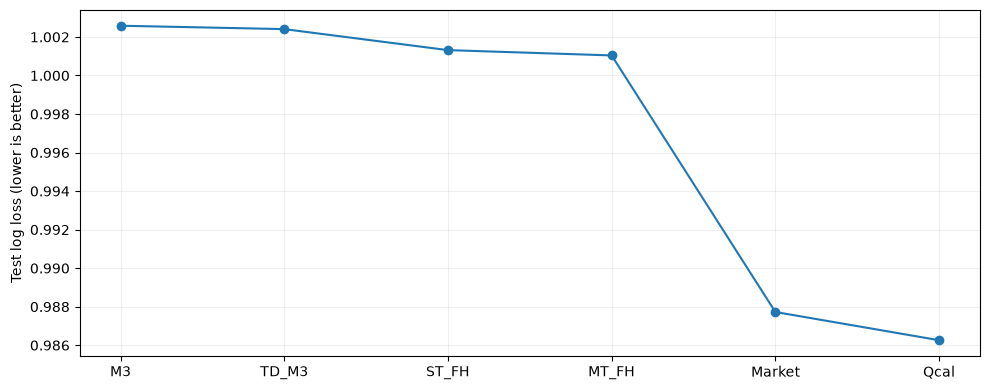

完成： /home/euan_li/projects/AML/reports/lstm_multitask/RESULTS.zh-CN.md


In [9]:
def md_table(frame):
    columns = list(frame.columns)
    lines = ['| '+' | '.join(columns)+' |','| '+' | '.join(['---']*len(columns))+' |']
    for record in frame.itertuples(index=False,name=None):
        values = [f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v) for v in record]
        lines.append('| '+' | '.join(values)+' |')
    return '\n'.join(lines)



input_rows=[]
for group in GROUPS:
    for kind,label in [('single','ST'),('multi','MT')]:
        input_rows.append({'model':label+'_'+group,'base_inputs':'Division one-hot, elo_diff, h2h_count, h2h_missing','recent_sequence':'home+away each 5 x [points,GD,draw,age]' if GROUPS[group][0] else 'none','h2h_sequence':'all prior x [points difference,GD,draw,age]' if GROUPS[group][1] else 'none','training_targets':'FTResult + q_H/q_D/q_A' if kind=='multi' else 'FTResult','outputs':'outcome probabilities + odds probabilities' if kind=='multi' else 'outcome probabilities','lambda':selected[group][kind]['lambda']})
pd.DataFrame(input_rows).to_csv(OUT/'model_inputs.csv',index=False)
main_names=['M0','M1','M2','M3','TD_M1','TD_M2','TD_M3','ST_B','ST_F','ST_H','ST_FH','MT_B','MT_F','MT_H','MT_FH','Market','Qcal']
report='# LSTM单任务与硬参数共享多任务：实际运行结果\n\n'
report+='## 做了什么\n\n近期仍是双方各5场；交锋使用全部此前比赛。近期主客共用一个LSTM，交锋用另一个LSTM；两任务共用这两个编码器及32单元中间层，最后各自输出H/D/A三项概率。只有B的组是MLP。\n\n'
report+='赛果损失CE，加λ倍赔率KL。赔率仅作辅助训练目标，推断不需要本场赔率；它仍是一种训练期市场信息监督，不能叫“完全不利用赔率”。任务可能互助，也可能互相干扰。没有强迫多任务胜出。\n\n'
report+='## 输入和输出\n\n'
report+=md_table(pd.DataFrame(input_rows))+'\n\n'
report+='每条近期记录为该队积分、净胜球、平局标记、距本场天数；每条交锋为本场主队减客队的积分差、主队净胜球、平局标记、距本场天数。积分/3、净胜球/5、年龄log(1+天数)/log366，不用测试集估计比例。每个编码器8维输出，近期取主客表示之差和均值；交锋取主队视角表示。隐藏序列按90/365天半衰期加权，空交锋全0且B有缺失标记。8维表示没有预先定义的“优势”单位。\n\n'
report+='## 如何选择与运行\n\n训练106288场（≤2020），验证12598场（2021—22），测试11772场（2023—24）；2025不参与。4组×4个λ在验证集选轮数，主目标均为赛果Log Loss；λ为0保留单任务，正λ中选一个多任务。各选择以3个seed在截至2022年的118886场重训。主表为3个seed概率平均，各seed见seed_scores.csv。测试不用于挑seed、λ或轮数。\n\n'
report+=md_table(pd.DataFrame([{'group':g,'single_epochs':s['single']['epochs'],'multi_lambda':s['multi']['lambda'],'multi_epochs':s['multi']['epochs'],'single_val_loss':s['single']['validation_log_loss'],'multi_val_loss':s['multi']['validation_log_loss'],'validation_preferred':s['validation_preferred']} for g,s in selected.items()]))+'\n\n'
report+='## 真实赛果预测\n\n'
report+=md_table(scores.set_index('model').loc[main_names,['log_loss','brier','accuracy']].reset_index())+'\n\n'
report+='## 多任务是否优于同结构单任务\n\n'
report+=md_table(paired.loc[paired.left.isin(['MT_B','MT_F','MT_H','MT_FH'])&paired.right.isin(['ST_B','ST_F','ST_H','ST_FH'])])+'\n\n'
report+='负差值表示左边更好；区间跨0不能断言稳定改善。区间是测试期28天块、按年分层bootstrap的描述性95%区间（1000次），不包含训练或选参不确定性，也未校正多重比较。\n\n'
report+='## 赔率拟合\n\n'
report+=md_table(scores.loc[scores.model.isin(['O0','O1','O2','O3','TD_O1','TD_O2','TD_O3','MT_B_odds','MT_F_odds','MT_H_odds','MT_FH_odds']),['model','kl_to_odds','odds_probability_mae']])+'\n\n'
report+='赔率表用多任务的独立赔率头；赛果表用赛果头。单任务赔率头没有受训，不报告。λ按赛果而非赔率选择，所以多任务赔率头不一定达到最优赔率拟合。能拟合市场不等于能赚钱，也不能证明博彩公司用了同样特征。\n\n'
report+='## 如何客观解读\n\n'
for g in GROUPS:
    r=paired.loc[(paired.left=='MT_'+g)&(paired.right=='ST_'+g)].iloc[0]
    report+=f"- {g}：多任务−单任务Log Loss={r.difference:.6f}，95%区间[{r.ci_low:.6f}, {r.ci_high:.6f}]。"+('区间跨0，差异不确定。' if r.ci_includes_zero else ('多任务的测试损失较低。' if r.difference<0 else '多任务的测试损失较高。'))+'\n'
report+='\n这是小型网络的第一版实证，不代表LSTM的性能上限。与逻辑回归的差别包含序列信息保留、非线性预测层和（MT）训练期赔率监督；不能把全部差异归功于LSTM。比较ST和MT才较直接检验这个辅助任务。训练seed有限，λ只用一个seed选择；还没有独立的非线性统计特征控制实验。年龄进入网络，信息量也与统计摘要不同。\n\n'
report+='此次LSTM未实现“本场赔率作为输入”的增量模型，所以不由此声称在给定赔率后历史仍有增益；该问题当前只有time_decay和旧baseline中的Q系列证据。无需把每个方向一次堆入第一版。\n\n'
report+='2023—24此前已查看，是后续分析。结论限于Elo完整、近期5场完整、赔率有效样本及当前参数；原始日期和现有Elo按项目约定直接使用。\n'
(OUT/'RESULTS.zh-CN.md').write_text(report,encoding='utf-8')
checks={'sequence_cache_verified':True,'strict_past_ages':True,'padding_invariance':True,'empty_h2h_zero':True,'both_tasks_reach_both_encoders':True,'gradient_checks':gradient_checks,'train_only_base_preprocessing':True,'no_current_odds_in_forward':True,'saved_models_reload_checked':True,'test_matches':len(test),'final_seeds':SEEDS,'raw_unchanged':verify_raw()==raw_hashes,'cleaned_unchanged':digest(cleaned_path)==cleaned_hash,'finished_utc':datetime.now(timezone.utc).isoformat()}
(OUT/'checks.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
fig,ax=plt.subplots(figsize=(10,4))
names=['M3','TD_M3','ST_FH','MT_FH','Market','Qcal']
ax.plot(names,scores.set_index('model').loc[names,'log_loss'],'o-');ax.set_ylabel('Test log loss (lower is better)');ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=160);plt.show()
print('完成：',OUT/'RESULTS.zh-CN.md')